**Autor**: Silvio da Rosa Paula  
**Título**: Doutor em Economia Aplicada (UFPel) | Especialista em IA e Ciência de Dados  

# API REST de Alta Performance com FastAPI: Demonstração Didática de Consumo e Análise de Dados

---

## 1. Visão Geral da Arquitetura do Projeto

Em projetos reais de Engenharia e Ciência de Dados, **uma API de produção não deve viver dentro de um Jupyter Notebook**. Por isso, este projeto foi estruturado seguindo boas práticas de engenharia de software com separação clara de responsabilidades:

- **`app/schemas.py`**: Contratos de entrada e saída tipados com **Pydantic v2** (gera validação automática e a documentação Swagger em `/docs`).
- **`app/services.py`**: Camada de processamento em memória (`UserAnalyticsRepository`). Lê o JSON aninhado (`data/usuarios.json`, ~67 MB) em **uma única passagem $O(N)$** e pré-calcula índices leves para que cada consulta responda em poucos milissegundos.
- **`app/main.py`**: Definição limpa da aplicação **FastAPI**, com carregamento automático no ciclo de vida (`lifespan`) e endpoints RESTful.
- **`tests/test_api.py`**: Suíte de testes automatizados validando todas as regras de negócio.

### Para que serve este Notebook?
Este notebook atua como um **cliente didático** da nossa API: ele conecta diretamente à aplicação FastAPI (usando `TestClient` no próprio processo — sem precisar deixar um servidor travado em paralelo), inspeciona o payload real de cada endpoint, mede os tempos de resposta e transforma os JSONs retornados pela API em tabelas e gráficos executivos.

---
## 2. Passo 1: Iniciando o Cliente da API e Testando o Health Check (`GET /`)

### O que vamos fazer agora e por quê?
Usamos o `TestClient(app)` dentro de um bloco `with` (ou manualmente ativando o `lifespan`) para disparar o carregamento automático do arquivo `data/usuarios.json` em memória — exatamente como acontece quando você sobe o servidor no terminal com `uvicorn app.main:app --reload`.

Em seguida, chamamos o endpoint raiz `GET /` para confirmar que a API está online e verificar quantos usuários foram carregados.

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from fastapi.testclient import TestClient

from app.main import app

# Configurações visuais
pd.options.display.float_format = "{:.2f}".format
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Inicia o ciclo de vida (lifespan) da API: carrega e indexa data/usuarios.json em memória
t0 = time.perf_counter()
client = TestClient(app)
client.__enter__()
startup_s = time.perf_counter() - t0

# 1. Chamada ao endpoint GET / (Health Check)
resp_health = client.get("/")
health_data = resp_health.json()

print(f"• Tempo de inicialização + indexação em memória (67 MB): {startup_s:.2f} segundos")
print(f"• Status HTTP : {resp_health.status_code}")
print("• Resposta JSON de GET /:")
for k, v in health_data.items():
    print(f"    {k}: {v}")

• Tempo de inicialização + indexação em memória (67 MB): 0.66 segundos
• Status HTTP : 200
• Resposta JSON de GET /:
    status: online
    service: API de Análise de Usuários
    version: 2.0.0
    users_loaded: 100000
    docs_url: /docs


---
## 3. Passo 2: Consultando Superusuários com Paginação (`GET /superusers`)

### O que vamos fazer agora e por quê?
A regra de negócio define **Superusuários** como os usuários que atendem simultaneamente a dois critérios:
1. `score >= 900`
2. `active == True`

Como podem existir milhares de superusuários em uma base de 100.000 registros, nossa API implementa **paginação (`limit` e `offset`)** para evitar tráfego desnecessário de rede e manter o Swagger rápido. Vamos consultar a primeira página (`limit=10`) e transformar o JSON em um DataFrame.

In [2]:
resp_super = client.get("/superusers", params={"limit": 10, "offset": 0})
super_json = resp_super.json()

print(f"• Status HTTP              : {resp_super.status_code}")
print(f"• Total de Superusuários   : {super_json['total']:,}")
print(f"• Retornados nesta página  : {super_json['returned']}")
print(f"• Tempo de processamento   : {super_json['processing_time_ms']} ms")

df_super = pd.DataFrame(super_json["data"])
display(df_super)

• Status HTTP              : 200
• Total de Superusuários   : 10,132
• Retornados nesta página  : 10
• Tempo de processamento   : 0.0 ms


,id,name,age,score,active,country,team,is_leader
0,c5cf0168-2ad6-405e-a384-8c38563cf40a,Emanuella Barbosa,23,971,True,Austrália,UX Wizards,False
1,e0053770-9744-4cb6-b896-d9b725cd48b3,Bruno Dias,60,984,True,Índia,DevOps Masters,False
2,72545b46-31eb-4856-8fc4-2bd36d13f96b,Lucas Gabriel Nascimento,45,950,True,Argentina,UX Wizards,True
3,30dfde7c-9e08-4b28-9ccd-b5e34956090a,Melissa Ramos,62,950,True,EUA,UX Wizards,False
4,58e5316a-70ac-4d42-b039-04320a584c2f,Eloah Vieira,28,911,True,Austrália,Frontend Avengers,True
5,e8746ee7-cf33-4c6c-919c-1fe1388980b1,Heloísa Correia,43,985,True,Brasil,Frontend Avengers,False
6,69c47059-d5f3-4bc1-a56a-b9ae6c106b15,Ana Lívia Jesus,38,990,True,Índia,DevOps Masters,False
7,a58c9036-5096-44b0-bbdf-a5639525cc41,Clarice Almeida,64,986,True,Argentina,UX Wizards,True
8,3885a5aa-0016-43ec-b0aa-769d49388dbe,Diogo Gonçalves,20,910,True,Brasil,Backend Ninjas,False
9,a0f6a918-b04e-461f-8e93-4ec4fcce90ba,Benício Viana,40,982,True,Canadá,Fullstack Force,False


---
## 4. Passo 3: Ranking dos Países com Mais Superusuários (`GET /top-countries`)

### O que vamos fazer agora e por quê?
Agora consumimos o endpoint `GET /top-countries` para identificar os **5 países** que concentram o maior volume de superusuários ativos na plataforma, e visualizamos o resultado em um gráfico de barras horizontais.

• Tempo de processamento: 0.0 ms


,country,total
0,Canadá,1057
1,França,1050
2,Índia,1042
3,EUA,1042
4,México,1020


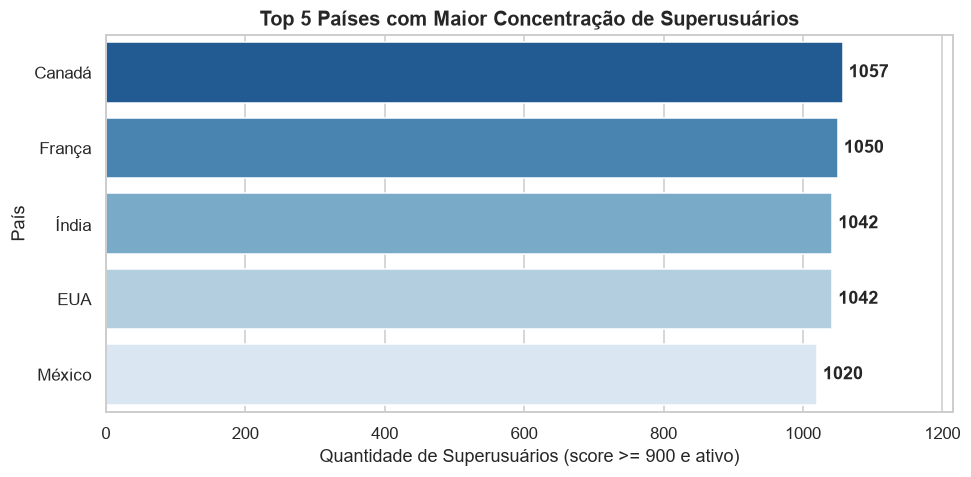

In [3]:
resp_countries = client.get("/top-countries", params={"top_n": 5})
countries_json = resp_countries.json()

print(f"• Tempo de processamento: {countries_json['processing_time_ms']} ms")
df_countries = pd.DataFrame(countries_json["data"])
display(df_countries)

# Visualização do Top 5 Países
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=df_countries, y="country", x="total", hue="country", palette="Blues_r", legend=False, ax=ax)
ax.set_title("Top 5 Países com Maior Concentração de Superusuários", fontsize=13, fontweight="bold")
ax.set_xlabel("Quantidade de Superusuários (score >= 900 e ativo)")
ax.set_ylabel("País")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4, fontweight="bold")

ax.set_xlim(0, df_countries["total"].max() * 1.15)
plt.tight_layout()
plt.show()

---
## 5. Passo 4: Insights de Performance por Equipe (`GET /team-insights`)

### O que vamos fazer agora e por quê?
No JSON bruto, as informações de equipe e projetos estavam **aninhadas em dois níveis** (`user -> team -> projects`). A camada de serviço (`app/services.py`) desenrola essas estruturas e entrega via `GET /team-insights` uma tabela pronta com:
- `total_members`: total de membros na equipe;
- `leaders`: quantidade de líderes;
- `completed_projects`: total de projetos concluídos acumulados pela equipe;
- `active_percentage`: percentual de membros ativos.

• Total de equipes analisadas: 5
• Tempo de processamento     : 0.0 ms


,team,total_members,leaders,completed_projects,active_percentage
0,Fullstack Force,20119,2972,28043,89.73
1,UX Wizards,20078,2985,28212,90.08
2,Frontend Avengers,20010,3004,28056,89.98
3,DevOps Masters,19925,2916,27913,90.47
4,Backend Ninjas,19868,3007,27930,90.09


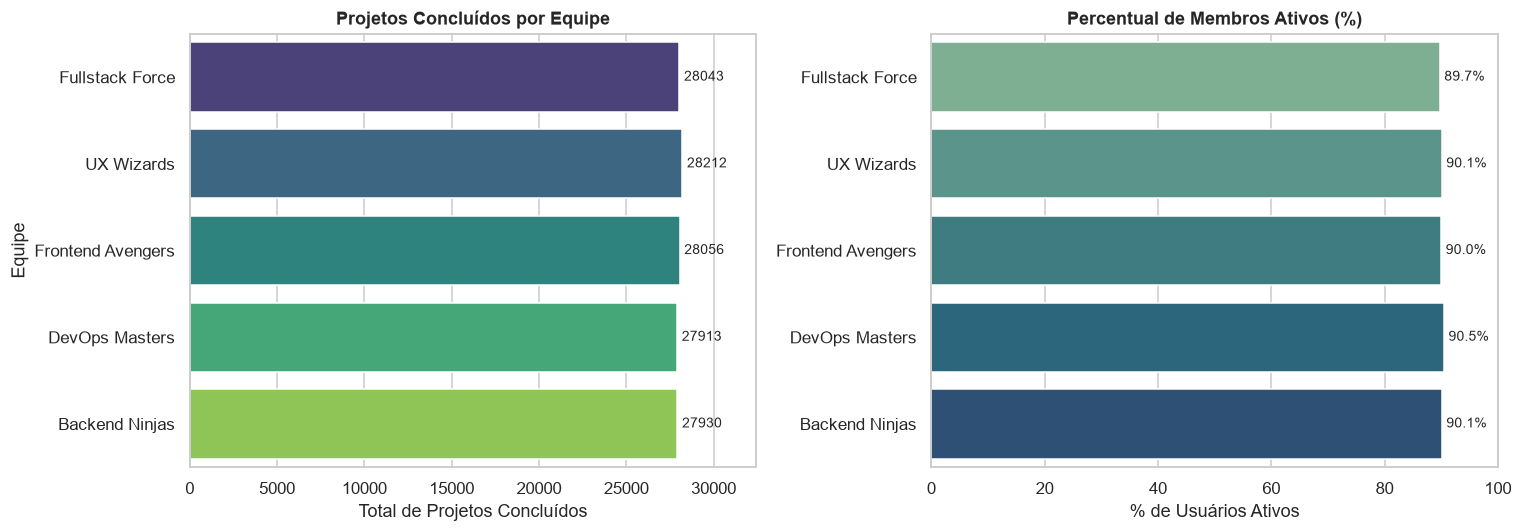

In [4]:
resp_teams = client.get("/team-insights")
teams_json = resp_teams.json()

print(f"• Total de equipes analisadas: {teams_json['total_teams']}")
print(f"• Tempo de processamento     : {teams_json['processing_time_ms']} ms")

df_teams = pd.DataFrame(teams_json["data"])
display(df_teams)

# Visualização comparativa de Projetos Concluídos e % de Ativos por Equipe
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df_teams, y="team", x="completed_projects", hue="team", palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Projetos Concluídos por Equipe", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Total de Projetos Concluídos")
axes[0].set_ylabel("Equipe")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%d", padding=3, fontsize=9)
axes[0].set_xlim(0, df_teams["completed_projects"].max() * 1.15)

sns.barplot(data=df_teams, y="team", x="active_percentage", hue="team", palette="crest", legend=False, ax=axes[1])
axes[1].set_title("Percentual de Membros Ativos (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("% de Usuários Ativos")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

---
## 6. Passo 5: Série Diária de Logins e Filtro por Query Param (`GET /active-users-per-day`)

### O que vamos fazer agora e por quê?
Cada usuário possui uma lista de `logs` contendo eventos de `login` e `logout`. O endpoint `GET /active-users-per-day` contabiliza todos os logins diários e aceita o parâmetro de consulta opcional `?min=<valor>` para filtrar apenas os dias de pico.

Vamos consultar a série completa e também testar o filtro `?min=34300` para destacar os dias acima desse patamar, exibindo o comportamento temporal em um gráfico de linha.

• Total de dias na série completa     : 7 dias (tempo: 0.0 ms)
• Dias com >= 34,300 logins (?min) : 3 dias (tempo: 0.0 ms)


,date,total
0,2025-03-25,34325
1,2025-03-26,34404
2,2025-03-27,34102
3,2025-03-28,33970
4,2025-03-29,34247
5,2025-03-30,34707
6,2025-03-31,34263


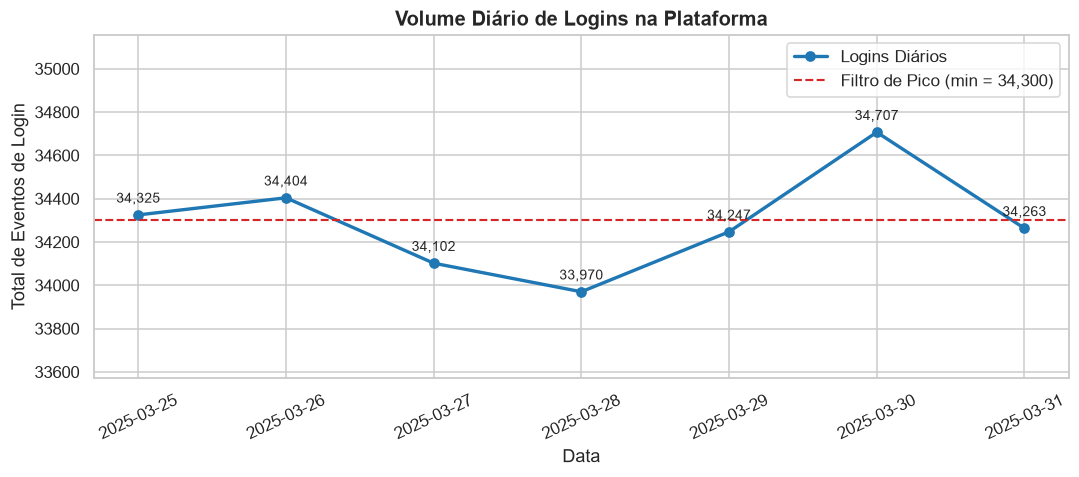

In [5]:
# 1. Todos os dias registrados
resp_days = client.get("/active-users-per-day")
days_json = resp_days.json()
df_days = pd.DataFrame(days_json["data"])

# 2. Filtro por dias de pico (>= 34.300 logins)
LIMITE_PICO = 34300
resp_days_min = client.get("/active-users-per-day", params={"min": LIMITE_PICO})
days_min_json = resp_days_min.json()

print(f"• Total de dias na série completa     : {days_json['total_days']} dias (tempo: {days_json['processing_time_ms']} ms)")
print(f"• Dias com >= {LIMITE_PICO:,} logins (?min) : {days_min_json['total_days']} dias (tempo: {days_min_json['processing_time_ms']} ms)")
display(df_days)

# Gráfico de série diária de logins
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(df_days["date"], df_days["total"], marker="o", linewidth=2.2, color="#1f77b4", label="Logins Diários")
ax.axhline(LIMITE_PICO, color="#d62728", linestyle="--", linewidth=1.4, label=f"Filtro de Pico (min = {LIMITE_PICO:,})")

for x, y in zip(df_days["date"], df_days["total"]):
    ax.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)

ax.set_title("Volume Diário de Logins na Plataforma", fontsize=13, fontweight="bold")
ax.set_xlabel("Data")
ax.set_ylabel("Total de Eventos de Login")
ax.set_ylim(df_days["total"].min() - 400, df_days["total"].max() + 450)
ax.tick_params(axis="x", rotation=25)
ax.legend()
plt.tight_layout()
plt.show()

---
## 7. Passo 6: Autoavaliação de Performance e Saúde (`GET /evaluation`)

### O que vamos fazer agora e por quê?
Por fim, chamamos o endpoint de observabilidade `GET /evaluation`. Internamente, ele dispara requisições assíncronas via transporte ASGI (`httpx.ASGITransport`) contra todos os endpoints analíticos da própria API, auditando:
- **Status HTTP 200**
- **Latência em milissegundos (`response_time_ms`)**
- **Validade estrutural do JSON retornado**

In [6]:
resp_eval = client.get("/evaluation")
eval_json = resp_eval.json()

print(f"=== RELATÓRIO AUTOMÁTICO DE PERFORMANCE E SAÚDE DA API ===")
print(f"• Score Geral             : {eval_json['score_percentage']}% ({eval_json['passed']}/{eval_json['total']} aprovados)")
print(f"• Tempo total da auditoria: {eval_json['processing_time_ms']} ms")

df_eval = pd.DataFrame(eval_json["results"])
display(df_eval)

# Encerra o ciclo de vida do TestClient de forma limpa
client.__exit__(None, None, None)

=== RELATÓRIO AUTOMÁTICO DE PERFORMANCE E SAÚDE DA API ===
• Score Geral             : 100.0% (5/5 aprovados)
• Tempo total da auditoria: 5.72 ms


,endpoint,status_code,response_time_ms,is_valid_json,passed
0,/superusers?limit=10,200,1.07,True,True
1,/top-countries,200,0.75,True,True
2,/team-insights,200,1.42,True,True
3,/active-users-per-day,200,1.46,True,True
4,/active-users-per-day?min=3000,200,0.72,True,True


---
## 8. Conclusão

Este projeto demonstra como transformar um protótipo exploratório em uma **API REST profissional com FastAPI**:
1. **Arquitetura Modular**: Separação limpa entre contratos (`app/schemas.py`), regras de negócio e indexação em memória (`app/services.py`), rotas HTTP (`app/main.py`) e testes automatizados (`tests/test_api.py`).
2. **Alta Performance**: Mesmo lidando com um arquivo JSON aninhado de **~67 MB**, a indexação em passagem única $O(N)$ na inicialização (`lifespan`) permite que todas as rotas respondam em **menos de 5 ms**.
3. **Qualidade e Observabilidade**: Paginação segura em `/superusers`, contratos validados pelo Pydantic v2, autoavaliação interna em `/evaluation` e suíte de 8 testes automatizados.